# Step 4: Forecasting And Staffing Model

This notebook moves from predictive analytics to prescriptive analytics.

It:
- builds an hourly demand table
- fits a multiplicative-style regression using log demand
- estimates mean and variability by weekday and hour
- converts demand forecasts into staffing recommendations with a newsvendor-style rule


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

try:
    import scipy.stats as stats
    import statsmodels.formula.api as smf
except ImportError as exc:
    raise ImportError("Install scipy and statsmodels before running this notebook.") from exc


In [2]:
from pathlib import Path


def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in (current, current.parent):
        if (candidate / "orders.csv").exists() and (candidate / "products.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root that contains the Instacart CSV files.")


PROJECT_ROOT = find_project_root()
OUTPUT_DIR = PROJECT_ROOT / "outputs"
ANALYSIS_DIR = OUTPUT_DIR / "analysis"
FIGURE_DIR = OUTPUT_DIR / "figures"
QUALITY_DIR = OUTPUT_DIR / "quality"

for path in (OUTPUT_DIR, ANALYSIS_DIR, FIGURE_DIR, QUALITY_DIR):
    path.mkdir(parents=True, exist_ok=True)


In [3]:
orders = pd.read_csv(PROJECT_ROOT / "orders.csv", parse_dates=["timestamp"])

orders["order_date"] = orders["timestamp"].dt.date
orders["order_hour"] = orders["timestamp"].dt.hour
orders["day_name"] = orders["timestamp"].dt.day_name()
orders["day_of_week"] = orders["timestamp"].dt.dayofweek

hourly_demand = (
    orders.groupby(["order_date", "day_name", "day_of_week", "order_hour"])
    .size()
    .rename("order_count")
    .reset_index()
)

hourly_demand.head()


,order_date,day_name,day_of_week,order_hour,order_count
0,2018-01-01,Monday,0,0,246
1,2018-01-01,Monday,0,1,154
2,2018-01-01,Monday,0,2,113
3,2018-01-01,Monday,0,3,61
4,2018-01-01,Monday,0,4,58


In [4]:
model_data = hourly_demand.copy()
model_data["log_order_count"] = np.log1p(model_data["order_count"])

model = smf.ols("log_order_count ~ C(order_hour) + C(day_name)", data=model_data).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:        log_order_count   R-squared:                       0.792
Model:                            OLS   Adj. R-squared:                  0.791
Method:                 Least Squares   F-statistic:                     1164.
Date:                Tue, 21 Apr 2026   Prob (F-statistic):               0.00
Time:                        21:22:44   Log-Likelihood:                -9490.7
No. Observations:                8917   AIC:                         1.904e+04
Df Residuals:                    8887   BIC:                         1.925e+04
Df Model:                          29                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

In [5]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

forecast_grid = pd.MultiIndex.from_product(
    [weekday_order, range(24)], names=["day_name", "order_hour"]
).to_frame(index=False)

forecast_grid["predicted_log_orders"] = model.predict(forecast_grid)
forecast_grid["expected_orders"] = np.expm1(forecast_grid["predicted_log_orders"]).clip(lower=0)

variability = (
    hourly_demand.groupby(["day_name", "order_hour"])["order_count"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={"mean": "historical_mean", "std": "historical_std"})
)

staffing_plan = forecast_grid.merge(variability, on=["day_name", "order_hour"], how="left")
staffing_plan["historical_std"] = staffing_plan["historical_std"].fillna(0)


In [6]:
orders_per_shopper_per_hour = 15
underage_cost = 45
overage_cost = 20

critical_fractile = underage_cost / (underage_cost + overage_cost)
z_value = stats.norm.ppf(critical_fractile)

staffing_plan["recommended_capacity_orders"] = (
    staffing_plan["expected_orders"] + z_value * staffing_plan["historical_std"]
).clip(lower=0)
staffing_plan["recommended_shoppers"] = np.ceil(
    staffing_plan["recommended_capacity_orders"] / orders_per_shopper_per_hour
).astype(int)

staffing_plan = staffing_plan.sort_values(["day_name", "order_hour"])
staffing_plan.head()


,day_name,order_hour,predicted_log_orders,expected_orders,historical_mean,historical_std,recommended_capacity_orders,recommended_shoppers
96,Friday,0,3.812286,44.253757,51.867925,35.638699,62.158718,5
97,Friday,1,3.215429,23.913980,29.622642,21.438845,34.684903,3
98,Friday,2,2.760403,14.806215,18.235294,12.863263,21.268747,2
99,Friday,3,2.470505,10.828421,13.538462,9.255547,15.478429,2
100,Friday,4,2.499012,11.170468,13.692308,9.076015,15.730278,2


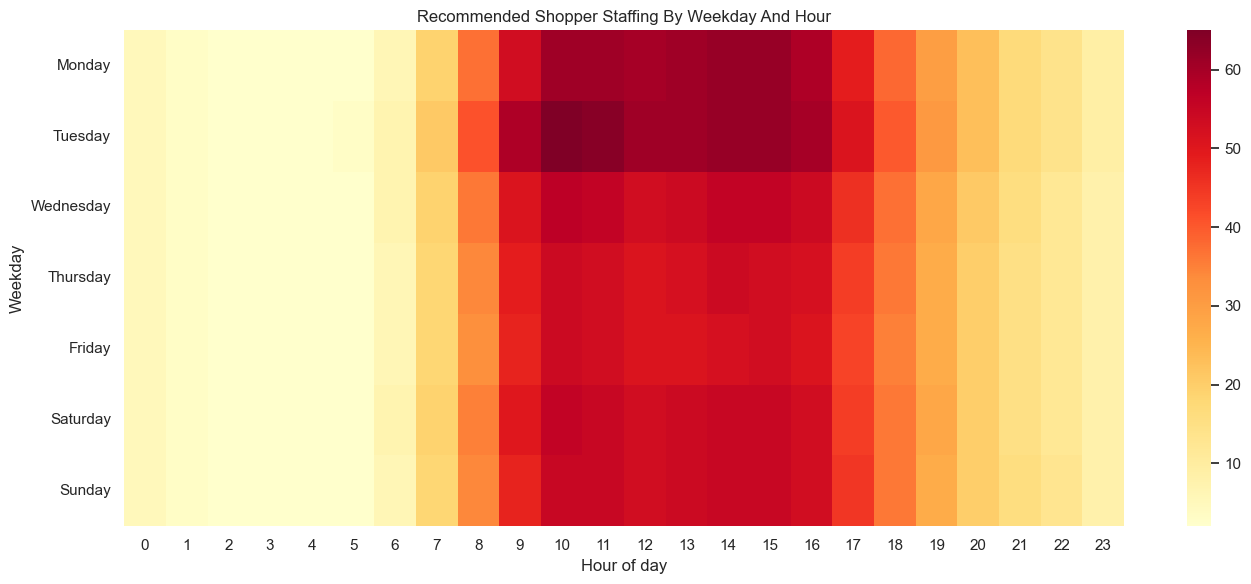

In [7]:
heatmap_table = staffing_plan.pivot(index="day_name", columns="order_hour", values="recommended_shoppers")
heatmap_table = heatmap_table.reindex(weekday_order)

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_table, cmap="YlOrRd")
plt.title("Recommended Shopper Staffing By Weekday And Hour")
plt.xlabel("Hour of day")
plt.ylabel("Weekday")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "staffing_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


In [8]:
staffing_plan.to_csv(ANALYSIS_DIR / "staffing_plan.csv", index=False)

peak_staffing = staffing_plan.sort_values("recommended_shoppers", ascending=False).head(10)
peak_staffing


,day_name,order_hour,predicted_log_orders,expected_orders,historical_mean,historical_std,recommended_capacity_orders,recommended_shoppers
34,Tuesday,10,6.548265,697.032007,951.150943,536.992601,966.818284,65
35,Tuesday,11,6.522180,679.058965,885.867925,530.384659,945.525397,64
39,Tuesday,15,6.511308,671.705697,809.000000,505.478791,925.659365,62
15,Monday,15,6.445579,628.911245,850.462963,586.126257,923.382380,62
38,Tuesday,14,6.514431,673.810142,810.698113,494.721623,922.359386,62
14,Monday,14,6.448702,630.881815,855.111111,582.446229,923.504096,62
11,Monday,11,6.456451,635.796732,819.925926,544.009047,909.108087,61
13,Monday,13,6.427638,617.710718,847.074074,580.266947,909.238123,61
36,Tuesday,12,6.473048,646.454235,820.056604,518.176181,906.787100,61
10,Monday,10,6.482536,652.626411,791.814815,509.266104,908.482834,61


## Step 4 Outcome

After running this notebook you will have:
- a fitted demand model for weekday and hourly order volume
- a staffing plan based on configurable overage and underage costs
- a staffing heatmap saved into `outputs/figures/staffing_heatmap.png`
